In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from torus_clock.data import load_rte, calendar_phases, make_windows
import pandas as pd

In [2]:
RAW = Path("../data/raw/rte")
files = sorted(RAW.glob("*.xls"))
print([f.name for f in files])

load = load_rte(*files)
print(load.index[0], "→", load.index[-1], "|", len(load), "hours |", load.isna().sum(), "missing")

['eCO2mix_RTE_Annuel-Definitif_2023.xls', 'eCO2mix_RTE_Annuel-Definitif_2024.xls', 'eCO2mix_RTE_Annuel-Definitif_2025.xls', 'eCO2mix_RTE_En-cours-Consolide.xls']
2022-12-31 23:00:00+00:00 → 2026-08-31 21:00:00+00:00 | 32135 hours | 6 missing


/tmp/ipykernel_30076/1557583767.py:10: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  week = local.groupby([local.index.dayofweek, local.index.hour]).mean().unstack()


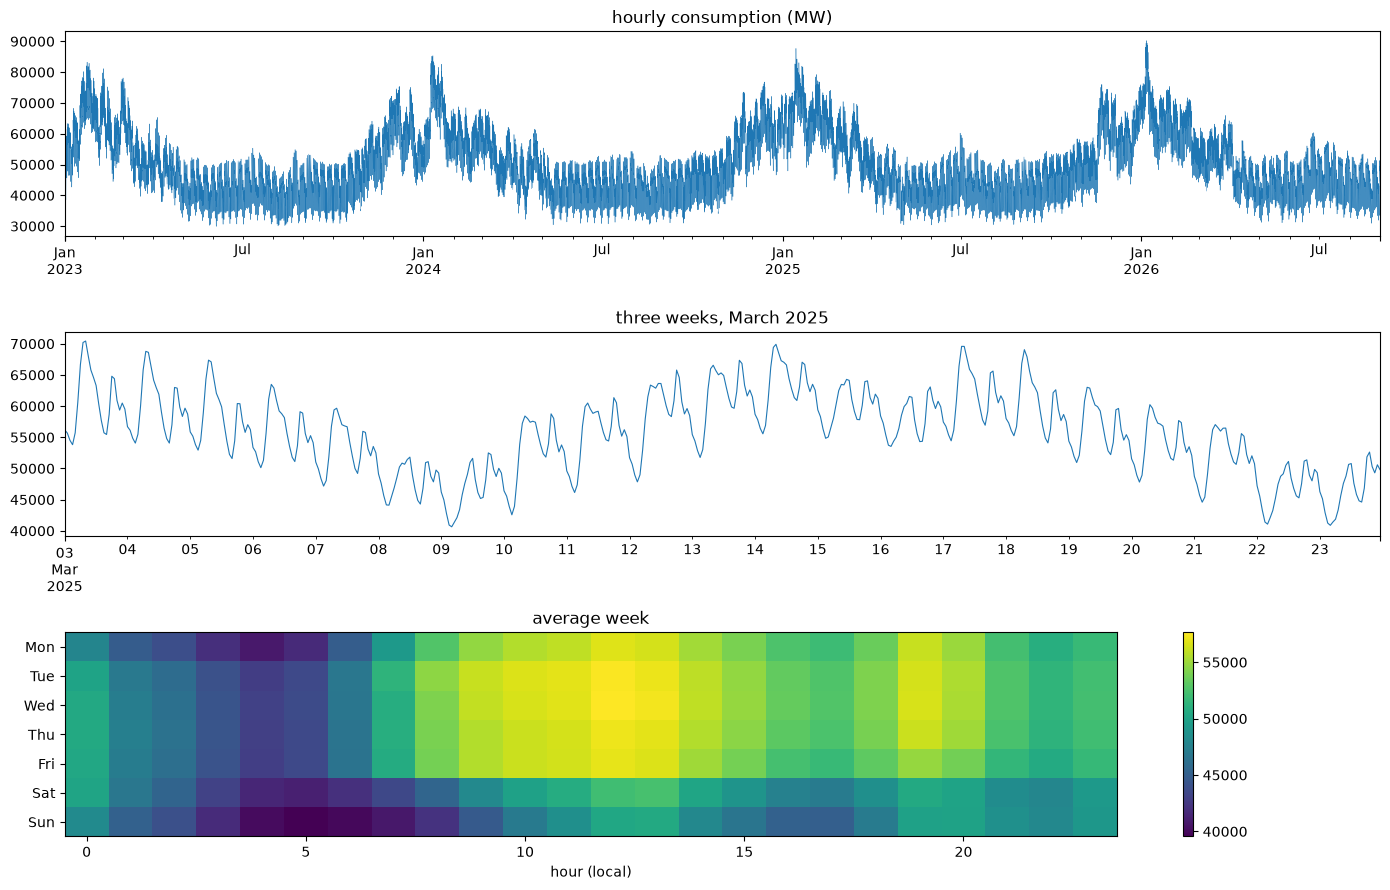

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9))

load.plot(ax=axes[0], lw=0.3)                                   # everything: seasons
axes[0].set_title("hourly consumption (MW)")

load["2025-03-03":"2025-03-23"].plot(ax=axes[1], lw=0.8)        # three weeks: daily + weekly cycle
axes[1].set_title("three weeks, March 2025")

local = load.tz_convert("Europe/Paris")                         # average week: weekday x hour
week = local.groupby([local.index.dayofweek, local.index.hour]).mean().unstack()
im = axes[2].imshow(week, aspect="auto", cmap="viridis")
axes[2].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[2].set_xlabel("hour (local)")
axes[2].set_title("average week")
plt.colorbar(im, ax=axes[2])

plt.tight_layout()
plt.show()

In [4]:
x_tr, idx_tr, d_tr, w_tr = make_windows(load, "2025-01-01", "2025-09-01")
x_te, idx_te, d_te, w_te = make_windows(load, "2025-10-01", "2026-09-01")
print(x_tr.shape, x_te.shape)

(311, 576) (439, 576)


In [5]:
import torch
from torus_clock.model import capture, load_model

model = load_model()
acts_tr, _ = capture(model, torch.tensor(x_tr[:, :512]))
acts_te, out_te = capture(model, torch.tensor(x_te[:, :512]))

patch_end = 16 * np.arange(32) + 15
labels = {"train": (d_tr[:, patch_end], w_tr[:, patch_end]),
          "test": (d_te[:, patch_end], w_te[:, patch_end])}

/home/bigburrito/icai/xai/torus-clock/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 143/143 [00:00<00:00, 2161.48it/s]


In [6]:
import pandas as pd
from torus_clock.probes import fit_probe, probe_score

def patches(x):                       # per-window normalised raw patches, NaN -> 0 like the model
    c = x[:, :512]
    z = (c - np.nanmean(c, 1, keepdims=True)) / np.nanstd(c, 1, keepdims=True)
    return np.nan_to_num(z).reshape(len(x), 32, 16)

reps = {"raw patch": (patches(x_tr), patches(x_te))}
reps.update({name: (acts_tr[name][:, :32].cpu().numpy(), acts_te[name][:, :32].cpu().numpy())
             for name in acts_tr})

rows = []
for name, (A_tr, A_te) in reps.items():
    row = {"layer": name}
    for key, i, period in [("daily", 0, 24), ("weekly", 1, 168)]:
        f = fit_probe(A_tr, labels["train"][i])
        row[key], row[key + " err h"] = probe_score(f, A_te, labels["test"][i], period)
    rows.append(row)
real_scores = pd.DataFrame(rows).set_index("layer")
real_scores.round(3)

,daily,daily err h,weekly,weekly err h
layer,,,,
raw patch,0.907,1.058,0.350,24.110
layer 0,0.985,0.359,0.489,19.300
layer 1,0.995,0.219,0.849,8.588
layer 2,0.997,0.196,0.905,6.233
layer 3,0.997,0.195,0.940,4.887
layer 4,0.996,0.201,0.944,4.514
layer 5,0.995,0.232,0.950,4.374
layer 6,0.995,0.249,0.954,4.087
encoder out,0.995,0.244,0.954,3.974


In [7]:
from torus_clock.probes import fit_probe, probe_score, wrap

f = fit_probe(acts_tr["layer 6"][:, :32].cpu().numpy(), labels["train"][1])
pred = f(acts_te["layer 6"][:, :32].cpu().numpy())
err_h = wrap(np.arctan2(pred[..., 1], pred[..., 0]) - labels["test"][1]) * 168 / (2 * np.pi)

true_day = (labels["test"][1] / (2 * np.pi) * 7).astype(int) % 7
pred_day = ((labels["test"][1] + err_h * 2 * np.pi / 168) / (2 * np.pi) * 7).astype(int) % 7

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(pd.Series(np.abs(err_h).ravel()).groupby(true_day.ravel()).median().set_axis(days).round(1))
print(pd.crosstab(pd.Series(true_day.ravel(), name="true").map(dict(enumerate(days))),
                  pd.Series(pred_day.ravel(), name="predicted").map(dict(enumerate(days))),
                  normalize="index").round(2))

Mon    4.4
Tue    4.1
Wed    4.3
Thu    4.1
Fri    4.1
Sat    3.9
Sun    3.9
dtype: float64
predicted   Fri   Mon   Sat   Sun   Thu   Tue   Wed
true                                               
Fri        0.77  0.00  0.09  0.01  0.13  0.00  0.00
Mon        0.00  0.87  0.00  0.00  0.00  0.12  0.00
Sat        0.13  0.00  0.77  0.10  0.00  0.00  0.00
Sun        0.00  0.10  0.12  0.78  0.00  0.00  0.00
Thu        0.10  0.00  0.01  0.00  0.77  0.00  0.12
Tue        0.00  0.08  0.00  0.00  0.00  0.76  0.16
Wed        0.01  0.00  0.00  0.00  0.12  0.08  0.78


In [8]:
from chronos.chronos_bolt import ChronosBoltModelForForecasting

torch.manual_seed(0)
untrained = ChronosBoltModelForForecasting(model.config).eval()
acts_u_tr, _ = capture(untrained, torch.tensor(x_tr[:, :512]))
acts_u_te, _ = capture(untrained, torch.tensor(x_te[:, :512]))

rows = []
for name in acts_u_tr:
    A_tr, A_te = acts_u_tr[name][:, :32].cpu().numpy(), acts_u_te[name][:, :32].cpu().numpy()
    row = {"layer": name}
    for key, i, period in [("daily", 0, 24), ("weekly", 1, 168)]:
        row[key], row[key + " err h"] = probe_score(fit_probe(A_tr, labels["train"][i]), A_te, labels["test"][i], period)
    rows.append(row)
pd.DataFrame(rows).set_index("layer").round(3)

,daily,daily err h,weekly,weekly err h
layer,,,,
layer 0,0.979,0.375,0.485,19.333
layer 1,0.979,0.375,0.485,19.333
layer 2,0.979,0.375,0.485,19.336
layer 3,0.979,0.375,0.485,19.331
layer 4,0.979,0.375,0.485,19.331
layer 5,0.979,0.375,0.485,19.338
layer 6,0.979,0.375,0.485,19.339
encoder out,0.980,0.361,0.484,19.233


In [9]:
from ripser import ripser
from sklearn.decomposition import PCA

def real_homology(acts_list, d_list, w_list, layer, shuffle=False, seed=0):
    A = np.concatenate([a[layer][:, :32].cpu().numpy().reshape(-1, 512) for a in acts_list])
    hour = (np.concatenate([d.ravel() for d in d_list]) / (2 * np.pi) * 24).astype(int) % 24
    day = (np.concatenate([w.ravel() for w in w_list]) / (2 * np.pi) * 7).astype(int) % 7
    if shuffle:
        p = np.random.default_rng(seed).permutation(len(hour)); hour, day = hour[p], day[p]
    C = np.stack([A[(day == d) & (hour == h)].mean(0) for d in range(7) for h in range(24)])   # [168, 512]
    C = C - C.mean(0); C = C / np.sqrt((C ** 2).sum(1).mean())
    C = PCA(len(C) - 1).fit_transform(C)
    dg = ripser(C, maxdim=2)["dgms"]
    return {f"H{k}": np.sort((g[:, 1] - g[:, 0])[np.isfinite(g[:, 1])])[::-1][:4].round(2) for k, g in enumerate(dg)}


tr_te = ([acts_tr, acts_te], [labels["train"][0], labels["test"][0]], [labels["train"][1], labels["test"][1]])
for layer in ["layer 0", "layer 3", "layer 6"]:
    print(layer, "trained ", real_homology(*tr_te, layer))
print("layer 6 shuffled", real_homology(*tr_te, "layer 6", shuffle=True))
print("layer 6 untrained", real_homology([acts_u_tr, acts_u_te], tr_te[1], tr_te[2], "layer 6"))

layer 0 trained  {'H0': array([0.48, 0.46, 0.44, 0.43]), 'H1': array([0.57, 0.53, 0.21, 0.17]), 'H2': array([0.03, 0.  , 0.  ])}
layer 3 trained  {'H0': array([0.49, 0.49, 0.48, 0.48]), 'H1': array([0.82, 0.39, 0.37, 0.18]), 'H2': array([0.06, 0.04, 0.04, 0.03])}
layer 6 trained  {'H0': array([0.47, 0.46, 0.46, 0.46]), 'H1': array([0.73, 0.71, 0.51, 0.17]), 'H2': array([0.12, 0.05, 0.04, 0.04])}
layer 6 shuffled {'H0': array([1.29, 1.29, 1.21, 1.2 ]), 'H1': array([0.12, 0.09, 0.09, 0.09]), 'H2': array([0.05, 0.05, 0.05, 0.05])}
layer 6 untrained {'H0': array([0.49, 0.46, 0.44, 0.43]), 'H1': array([0.6 , 0.54, 0.24, 0.2 ]), 'H2': array([0.05, 0.  , 0.  , 0.  ])}


In [10]:
import plotly.graph_objects as go

A = np.concatenate([a["layer 6"][:, :32].cpu().numpy().reshape(-1, 512) for a in (acts_tr, acts_te)])
hour = (np.concatenate([labels["train"][0].ravel(), labels["test"][0].ravel()]) / (2 * np.pi) * 24).astype(int) % 24
day = (np.concatenate([labels["train"][1].ravel(), labels["test"][1].ravel()]) / (2 * np.pi) * 7).astype(int) % 7
C = np.stack([A[(day == d) & (hour == h)].mean(0) for d in range(7) for h in range(24)])
P = PCA(3).fit_transform(C).reshape(7, 24, 3)

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig = go.Figure([go.Scatter3d(x=np.r_[P[d, :, 0], P[(d + 1) % 7, 0, 0]],      # each day as a path, joined to the next day's midnight
                              y=np.r_[P[d, :, 1], P[(d + 1) % 7, 0, 1]],
                              z=np.r_[P[d, :, 2], P[(d + 1) % 7, 0, 2]],
                              mode="lines+markers", marker_size=3, name=days[d]) for d in range(7)])
fig.write_html("../results/04_layer6_week_path.html")

In [11]:
A_tr6, A_te6 = acts_tr["layer 6"][:, :32].cpu().numpy(), acts_te["layer 6"][:, :32].cpu().numpy()
pca = PCA(50).fit(A_tr6.reshape(-1, 512))

for k in (0, 3, 10, 30):
    V = pca.components_[:k]                                   # top-k directions to remove
    drop = lambda A: A - (A @ V.T) @ V if k else A
    f = fit_probe(drop(A_tr6), labels["train"][1])
    print(k, "PCs removed: weekly", np.round(probe_score(f, drop(A_te6), labels["test"][1], 168), 3))

0 PCs removed: weekly [0.954 4.087]
3 PCs removed: weekly [ 0.768 10.415]
10 PCs removed: weekly [ 0.561 16.411]
30 PCs removed: weekly [ 0.268 27.758]


In [12]:
from ripser import ripser
from sklearn.decomposition import PCA


def homology_last32(A, daily_lab, weekly_lab):
    """Bars of the 168 (day, hour) cell averages. A: [n, 32, 512], labels: [n, 32]."""
    A = A.reshape(-1, A.shape[-1])
    hour = (daily_lab.ravel() / (2 * np.pi) * 24).astype(int) % 24
    day = (weekly_lab.ravel() / (2 * np.pi) * 7).astype(int) % 7
    C = np.stack([A[(day == d) & (hour == h)].mean(0) for d in range(7) for h in range(24)])
    C = C - C.mean(0)
    C = C / np.sqrt((C ** 2).sum(1).mean())
    dg = ripser(PCA(len(C) - 1).fit_transform(C), maxdim=2)["dgms"]
    bars = lambda g: np.sort((g[:, 1] - g[:, 0])[np.isfinite(g[:, 1])])[::-1]
    return bars(dg[1])[:3], bars(dg[2])[:2]


rows = []
for T in (512, 1024, 2048):
    xt_tr, _, dt_tr, wt_tr = make_windows(load, "2025-01-01", "2025-09-01", T=T)
    xt_te, _, dt_te, wt_te = make_windows(load, "2025-10-01", "2026-09-01", T=T)
    a_tr, _ = capture(model, torch.tensor(xt_tr[:, :T]))
    a_te, _ = capture(model, torch.tensor(xt_te[:, :T]))

    n = T // 16                                       # number of patches
    last = 16 * np.arange(n - 32, n) + 15             # end hour of each of the last 32 patches
    for layer in ("layer 3", "layer 6"):
        A_tr = a_tr[layer][:, n - 32:n].cpu().numpy()     # the same 32 most recent patches for every T
        A_te = a_te[layer][:, n - 32:n].cpu().numpy()
        score, err = probe_score(fit_probe(A_tr, wt_tr[:, last]), A_te, wt_te[:, last], 168)
        h1, h2 = homology_last32(np.concatenate([A_tr, A_te]),
                                 np.concatenate([dt_tr[:, last], dt_te[:, last]]),
                                 np.concatenate([wt_tr[:, last], wt_te[:, last]]))
        rows.append({"context": T, "layer": layer, "train windows": len(xt_tr),
                     "weekly": score, "weekly err h": err,
                     "H1 #1": h1[0], "H1 #2": h1[1], "H1 #3": h1[2], "H2 #1": h2[0], "H2 #2": h2[1]})
    del a_tr, a_te                                    # free memory before the next, larger context

context_scores = pd.DataFrame(rows).set_index(["context", "layer"])
context_scores.to_csv("../results/04_context_length.csv")
context_scores.round(3)

train windows  weekly  weekly err h  H1 #1  H1 #2  H1 #3  \
context layer                                                               
512     layer 3            311   0.940         4.887  0.817  0.390  0.365   
        layer 6            311   0.954         4.087  0.734  0.707  0.505   
1024    layer 3            281   0.939         4.733  0.798  0.383  0.356   
        layer 6            281   0.959         3.919  0.735  0.686  0.506   
2048    layer 3            221   0.889         5.181  0.815  0.377  0.348   
        layer 6            221   0.939         4.066  0.781  0.676  0.474   

                 H2 #1  H2 #2  
context layer                  
512     layer 3  0.058  0.038  
        layer 6  0.117  0.046  
1024    layer 3  0.049  0.047  
        layer 6  0.103  0.046  
2048    layer 3  0.046  0.038  
        layer 6  0.082  0.037

In [14]:
from sklearn.decomposition import PCA
from torus_clock.model import run_with_edit


def phase_plane(A, phase, n_bins=24):
    bins = (phase / (2 * np.pi) * n_bins).astype(int) % n_bins
    C = np.stack([A[bins == b].mean(0) for b in range(n_bins)])
    m = C.mean(0)
    U = PCA(2).fit(C - m).components_.T
    xy = (C - m) @ U
    ang, ctr = np.arctan2(xy[:, 1], xy[:, 0]), (np.arange(n_bins) + 0.5) * 2 * np.pi / n_bins
    sign = 1 if abs(np.exp(1j * (ang - ctr)).mean()) > abs(np.exp(1j * (ang + ctr)).mean()) else -1
    return U, m, sign


def rotation(U, m, sign, delta):
    c, s = np.cos(sign * delta), np.sin(sign * delta)
    M, U, m = (torch.tensor(a, dtype=torch.float32) for a in ([[c - 1, -s], [s, c - 1]], U, m))
    return lambda h: h + ((h - m) @ U @ M.T) @ U.T


day_of = lambda w: (w / (2 * np.pi) * 7).astype(int) % 7
hour_of = lambda d: (d / (2 * np.pi) * 24).astype(int) % 24
L = "layer 5"

# average token per (day, hour), from the training windows
A_tr = acts_tr[L][:, :32].cpu().numpy()
dd, hh = day_of(labels["train"][1]), hour_of(labels["train"][0])
mu = np.stack([[A_tr[(dd == d) & (hh == h)].mean(0) for h in range(24)] for d in range(7)])   # [7, 24, 512]

# average normalised week from the training windows -> what "+1 day" should do to each test forecast
z = (x_tr - np.nanmean(x_tr[:, :512], 1, keepdims=True)) / np.nanstd(x_tr[:, :512], 1, keepdims=True)
avg = np.array([[np.nanmean(z[(day_of(w_tr) == d) & (hour_of(d_tr) == h)]) for h in range(24)] for d in range(7)])
Df, Hf = day_of(w_te[:, 512:]), hour_of(d_te[:, 512:])
intended = np.nanstd(x_te[:, :512], 1, keepdims=True) * (avg[(Df + 1) % 7, Hf] - avg[Df, Hf])   # [n_te, 64]

context_te = torch.tensor(x_te[:, :512])
with torch.no_grad():
    base_te = model(context_te).quantile_preds


def effect(edit):
    realised = (run_with_edit(model, context_te, L, edit).quantile_preds[:, 4] - base_te[:, 4]).numpy()
    ok = np.isfinite(intended) & np.isfinite(realised)
    slope = (realised[ok] * intended[ok]).sum() / (intended[ok] ** 2).sum()
    return round(slope, 3), round(np.corrcoef(realised[ok], intended[ok])[0, 1], 3)


dt, ht = day_of(labels["test"][1]), hour_of(labels["test"][0])
perm = np.random.default_rng(0).permutation(7)
shift = torch.tensor(mu[(dt + 1) % 7, ht] - mu[dt, ht], dtype=torch.float32)          # move each token to the next day
shift_r = torch.tensor(mu[perm[dt], ht] - mu[dt, ht], dtype=torch.float32)            # control: scrambled days
U, m, sign = phase_plane(A_tr.reshape(-1, 512), labels["train"][1].reshape(-1), n_bins=28)

print("mean shift (+1 day):", effect(lambda h: h + shift))
print("rotation   (+1 day):", effect(rotation(U, m, sign, 2 * np.pi / 7)))
print("scrambled control:  ", effect(lambda h: h + shift_r))

mean shift (+1 day): (np.float32(0.84), np.float64(0.927))
rotation   (+1 day): (np.float32(0.133), np.float64(0.208))
scrambled control:   (np.float32(0.727), np.float64(0.644))


In [15]:
def intended_for(k):
    return np.nanstd(x_te[:, :512], 1, keepdims=True) * (avg[(Df + k) % 7, Hf] - avg[Df, Hf])

targets = {k: intended_for(k) for k in range(1, 7)}
M = np.zeros((6, 6))
for i, k in enumerate(range(1, 7)):
    shift_k = torch.tensor(mu[(dt + k) % 7, ht] - mu[dt, ht], dtype=torch.float32)
    realised = (run_with_edit(model, context_te, L, lambda h: h + shift_k).quantile_preds[:, 4] - base_te[:, 4]).numpy()
    for j, kk in enumerate(range(1, 7)):
        ok = np.isfinite(targets[kk]) & np.isfinite(realised)
        M[i, j] = np.corrcoef(realised[ok], targets[kk][ok])[0, 1]

pd.DataFrame(M, index=[f"edit +{k}d" for k in range(1, 7)],
             columns=[f"target +{k}d" for k in range(1, 7)]).round(2)

,target +1d,target +2d,target +3d,target +4d,target +5d,target +6d
edit +1d,0.93,0.69,0.39,0.28,0.27,-0.03
edit +2d,0.66,0.93,0.72,0.47,0.41,0.29
edit +3d,0.35,0.71,0.93,0.72,0.48,0.29
edit +4d,0.33,0.48,0.72,0.94,0.75,0.39
edit +5d,0.23,0.42,0.48,0.70,0.94,0.69
edit +6d,-0.05,0.26,0.36,0.39,0.69,0.92
